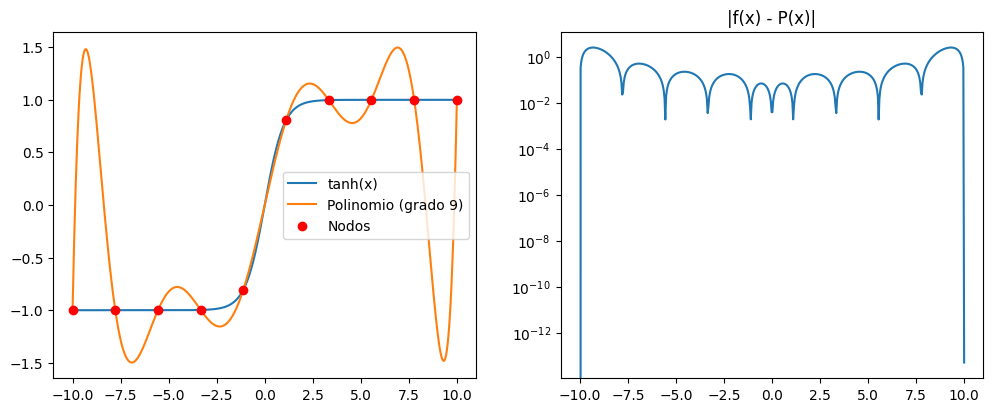

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#definmos diferencia dividida
def difer(puntos):
    n = len(puntos) - 1
    Fs = [np.zeros(n + 1)]                      # columna 0: valores f(x_i)
    for i in range(n + 1):
        Fs[0][i] = puntos[i][1]
    for i in range(1, n + 1):
        Fs.append(np.zeros(n + 1 - i))          # columna i: diferencias de orden i
        for j in range(1, i + 1):
            Fs[j][i-j] = (Fs[j-1][i-j+1] - Fs[j-1][i-j])/(puntos[i][0] - puntos[i-j][0])
    return [Fs[i][0] for i in range(n + 1)]     # primera entrada de cada columna

#se evalua el polinomio de Newton
def poly_lagrange(x, coefs, puntos):
    return sum(coefs[n]*np.prod([(x - puntos[i,0]) for i in range(n)])
               for n in range(len(coefs)))

# 10 valores desde -10 a 10 en f(x)
xp = np.linspace(-10, 10, 10)
puntos = np.array([[xi, np.tanh(xi)] for xi in xp])
coefs = difer(puntos)                           # polinomio de grado 9

#se evalua la funcion
x = np.linspace(-10, 10, 500)
exact = np.tanh(x)
P = np.array([poly_lagrange(xi, coefs, puntos) for xi in x])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

#función vs. polinomio
ax[0].plot(x, exact, label='tanh(x)')
ax[0].plot(x, P, label='Polinomio (grado 9)')
ax[0].scatter(puntos[:,0], puntos[:,1], color='red', zorder=5, label='Nodos')
ax[0].legend()

#error absoluto en escala log
ax[1].semilogy(x, np.abs(exact - P))
ax[1].set_title('|f(x) - P(x)|')
plt.show()